# Features from data

This lesson covers reading a recording from a file, finding peaks and crossings in an array, and turning them into a physical quantity.

The recording comes from a geotechnical centrifuge test of rock blocks resting on a slope. The base of the model was shaken back and forth, one accelerometer measured the base, and another was glued to a block that could slide down the slope. The files hold the base and block accelerations in g. The video [Test_10.mp4](Test_10.mp4) in this folder shows the test.

In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

## Two versions of the same recording

1. `sliding_block_accel.csv` stores a time column next to the base and block accelerations. 
2. `sliding_block_accel_dt.csv` stores the same base and block accelerations with no time column, and the sampling interval written as text at the top of the file. 
   
   
The second layout is poor practice, because a program has to dig the number out of a sentence, but many instruments write files that way. 

Let's look at the first lines of each before reading anything:

In [2]:
fname = "sliding_block_accel_dt.csv"
with open(fname) as f:
    for i in range(8):
        print(f.readline().strip())

dt: 0.002 seconds

base acceleration (g),block acceleration (g)
-0.0009,-0.0012
-0.0018,-0.0027
-0.0013,-0.0006
-0.0027,-0.0006
-0.0004,-0.0020


## A file with a time column

`np.loadtxt` reads a file of numbers into a two-dimensional array once it knows what separates the values and how many header rows to skip. A two-dimensional array is indexed `[row, column]`, and `:` means "all", so each column comes out as its own array:

In [3]:
data = np.loadtxt("sliding_block_accel.csv", delimiter=",",skiprows=1)
print(data.shape)

t = data[:,0]
a_base = data[:,1]
a_block = data[:,2]

(10000, 3)


## A file with the interval in its header

The first line of the second file is a sentence, `dt: 0.002 seconds`. Read that line as text, split off the number, and convert it with `float`. Then skip the three header rows (the sentence, a blank line, and the column names) and rebuild the time axis from the interval and the number of samples:

In [4]:
with open("sliding_block_accel_dt.csv") as f:
    first_line = f.readline()
# print(float(first_line.split(":")[1].split()[0]))
dt = float(first_line.split(":")[1].split()[0])
# print(dt)

data = np.loadtxt("sliding_block_accel_dt.csv", delimiter=",",skiprows=3)

a_base2 = data[:,0]
a_block2 = data[:,1]

t2 = dt * np.arange(len(a_base2))

The accelerations match, but the rebuilt time axis starts at zero while the first file starts at 0.002 s. Neither is wrong; the header doesn't say when the first sample was taken. A shift of one sample doesn't change any spacing between events, so it doesn't matter for a period.

## Look at it before anything else

The first thing to do with new data is plot it. The base shook for about 14 s with a steady rhythm, and the block followed it on one side of each cycle and fell short on the other. The rest of this lesson works with the base signal.

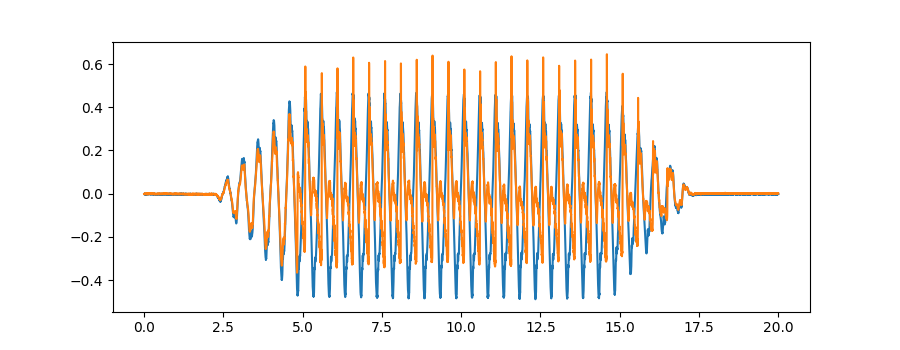

In [5]:
fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(t, a_base)
ax.plot(t, a_block)

## The biggest value, and where it is

`max()` gives the largest value; `argmax()` gives its **index**, which is how we find the time at which it happened:

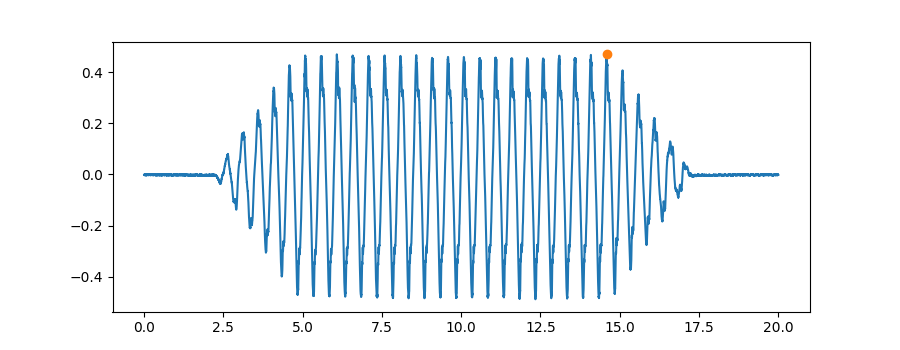

In [6]:
i = np.argmax(a_base)

fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(t, a_base)
ax.plot(t[i], a_base[i],"o")

## Local peaks

The global maximum is one number. The period needs **every** peak. A sample is a local peak when it is higher than both of its neighbours, which is a mask built from three slices of the same array. A threshold keeps the small wiggles out.

79 local peaks above the threshold in 5 seconds
spacing between them (s): [0.008 0.008 0.01  0.006 0.022 0.006 0.016 0.02  0.402 0.008 0.01  0.01
 0.026 0.022 0.024 0.398 0.01  0.006 0.004 0.012 0.022 0.004 0.022 0.02
 0.402 0.01  0.02  0.006 0.022 0.018 0.006 0.012 0.416 0.022 0.004 0.022
 0.02  0.018 0.004 0.402 0.006 0.004 0.004 0.016 0.026 0.02  0.004 0.012
 0.41  0.004 0.004 0.02  0.026 0.022 0.012 0.406 0.016 0.016 0.026 0.004
 0.018 0.02  0.406 0.008 0.008 0.008 0.004 0.026 0.02  0.022 0.398 0.008
 0.004 0.012 0.008 0.028 0.022 0.02 ]


Text(0, 0.5, 'base acceleration (g)')

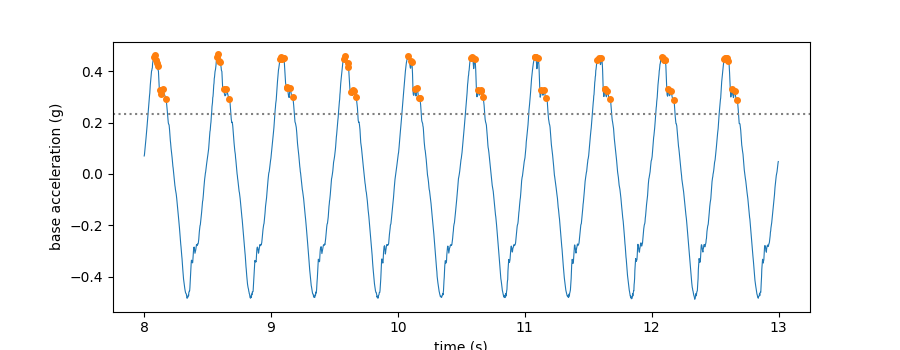

In [7]:
window = (t > 8) & (t < 13)                        # work on a window first
tw = t[window]
aw = a_base[window]

threshold = 0.5 * aw.max()
is_peak = (
    (aw[1:-1] > aw[:-2])            # the point is larger than the previous point
    & (aw[1:-1] > aw[2:])           # the point is larger than the next point
    & (aw[1:-1] > threshold))       # the point is larger than the threshold
peak_index = np.where(is_peak)[0] + 1              # +1 because the mask starts at the second sample
print(len(peak_index), "local peaks above the threshold in 5 seconds")
print("spacing between them (s):", np.round(np.diff(tw[peak_index]), 3))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(tw, aw, lw=0.8)
ax.plot(tw[peak_index], aw[peak_index], "o", ms=4)
ax.axhline(threshold, color="gray", linestyle=":")
ax.set_xlabel("time (s)")
ax.set_ylabel("base acceleration (g)")

Look at the spacings: about 0.4 s, then a run of values around 0.01 or 0.02 s. The top of each cycle, and the shoulder on its way down, are jagged, so one physical peak produces a cluster of local maxima. The fix is to keep only one peak per cluster: once a peak is accepted, ignore anything closer than some minimum spacing. That needs a loop, so it goes in a function we can reuse.

Text(0, 0.5, 'base acceleration (g)')

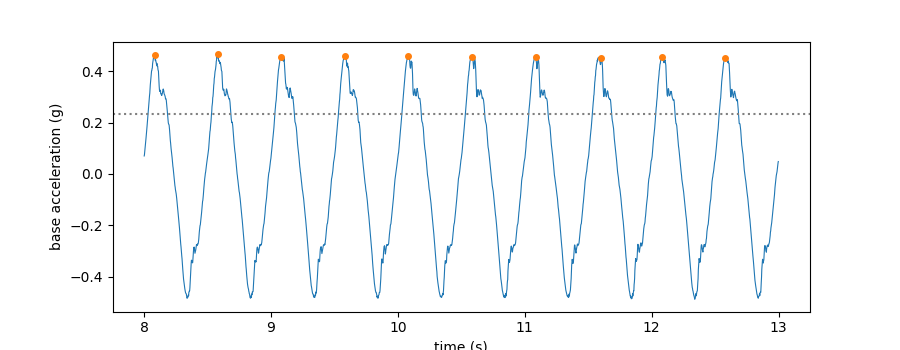

In [8]:
def find_peaks(t, a, threshold, min_spacing):
    is_peak = (
        (aw[1:-1] > aw[:-2])             # the point is larger than the previous point        
        & (aw[1:-1] > aw[2:])            # the point is larger than the next point   
        & (aw[1:-1] > threshold))        # the point is larger than the threshold   
    candidates = np.where(is_peak)[0]+1
    # Here, candidates contains all the points identified on the previous plot, which is more than we want.
    keep = []
    for i in candidates:
        if (
            len(keep)==0 # nothing has been added to the points to "keep" yet
            or 
            (t[i] - t[keep[-1]])>min_spacing # the time between a candidate and the last kept candidate is greater than min_spacing
            ):
            keep.append(i)
        elif a[i] > a[keep[-1]]: # the height of this candidate is greater than the previous kept candidate
            keep[-1] = i # replace the last candidate with this one.
    return np.array(keep)

window = (t > 8) & (t < 13)                        # work on a window first
tw = t[window]
aw = a_base[window]

peak_index = find_peaks(tw, aw, threshold, min_spacing=0.25)

fig, ax2 = plt.subplots(figsize=(9, 3.5))
ax2.plot(tw, aw, lw=0.8)
ax2.plot(tw[peak_index], aw[peak_index], "o", ms=4)
ax2.axhline(threshold, color="gray", linestyle=":")
ax2.set_xlabel("time (s)")
ax2.set_ylabel("base acceleration (g)")

## From spacing to period

The base swings forward and back once per cycle, so it reaches its largest forward acceleration **once per period**. The period is the mean spacing, its inverse is the frequency, and the spread of the spacings says how clean the measurement is:

In [9]:
peak_times = tw[peak_index]
spacing = np.diff(peak_times)
T_peaks = spacing.mean()
print(1/T_peaks)

2.001779359430605


## A second route: zero crossings

A signal that oscillates around a centre crosses that centre twice per period, and a crossing is a sign change between neighbours:

Text(0, 0.5, 'base acceleration (g)')

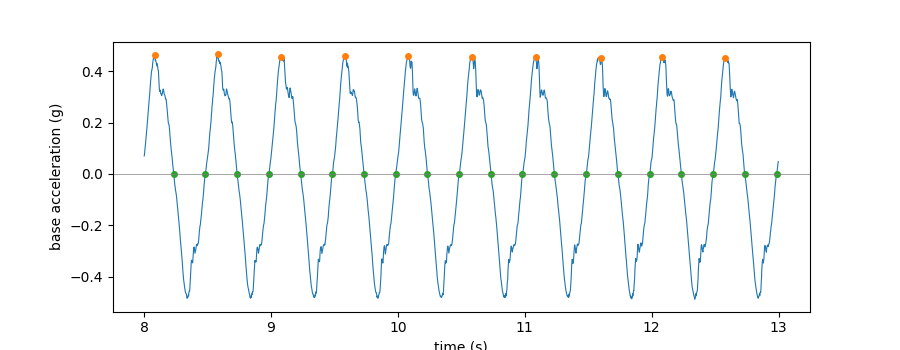

In [10]:
aw_centered = aw - aw.mean()
crossing = np.where(np.diff(np.sign(aw_centered)) != 0)[0]
T_crossing = 2* np.mean(np.diff(tw[crossing]))
fig, ax3 = plt.subplots(figsize=(9, 3.5))
ax3.plot(tw, aw, lw=0.8)
ax3.plot(tw[peak_index], aw[peak_index], "o", ms=4)
ax3.plot(tw[crossing],np.zeros(len(crossing)), "o", ms=4)
ax3.axhline(0,color="gray",lw=0.5)
ax3.set_xlabel("time (s)")
ax3.set_ylabel("base acceleration (g)")


## Checklist

* look at a data file as text before reading it
* `np.loadtxt(name, delimiter=",", skiprows=1)`, then one array per column with `data[:, k]`
* a number in a header is read with `readline`, `split` and `float`; `dt * np.arange(n)` rebuilds a time axis from an interval
* `argmax` for where the largest value is; a three-slice mask for every local peak; a threshold and a minimum spacing to get one peak per event
* `np.diff(np.sign(a - a.mean()))` finds crossings of the mean
* work on a time window first: `mask = (t > a) & (t < b)`
* a feature becomes a physical quantity through the model; two features that agree are a check, and the spread of the spacings is a warning